<a href="https://colab.research.google.com/github/sergeydorof/neural_networks_labs/blob/main/lab2/nn_lab2_a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Тут я вынесу все большие универсальные функции:
- prepare_mlp_data() - создает выборки для MLP
- prepare_rnn_data() - создает выборки для рекуррентных моделей
- train_and_evaluate() - универсальная функция для обучения и вывода графиков любой модели
- evaluate_and_plot_model() - универсальная функция для вывода метриков и графика истинных значений и предсказанных

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

def prepare_mlp_data(df, L_days=7, target_col='target_temp_next_day', test_size=0.15, val_size=0.15):
    """
    Готовит датасет для MLP: создает лаги, удаляет NaN,
    проводит хронологическое деление и масштабирует только не-циклические признаки.
    """
    window_size = int(L_days * 24)

    feature_cols = [col for col in df.columns if col != target_col]

    # 1. Сбор лагов в словарь
    lagged_dict = {}
    for col in feature_cols:
        for lag in range(1, window_size + 1):
            lagged_dict[f"{col}_t-{lag}"] = df[col].shift(lag)

    df_lagged = pd.DataFrame(lagged_dict, index=df.index)
    df_lagged[target_col] = df[target_col]

    # 2. Удаление пропусков
    df_lagged = df_lagged.dropna().reset_index(drop=True)

    # 3. Разделение на X и y
    X = df_lagged.drop(columns=[target_col])
    y = df_lagged[target_col]

    # 4. Хронологическое деление на выборки
    n = len(df_lagged)
    train_idx = int(n * (1 - test_size - val_size))
    val_idx = int(n * (1 - test_size))

    X_train, y_train = X.iloc[:train_idx], y.iloc[:train_idx]
    X_val, y_val = X.iloc[train_idx:val_idx], y.iloc[train_idx:val_idx]
    X_test, y_test = X.iloc[val_idx:], y.iloc[val_idx:]

    # 5. Масштабирование признаков (исключая синусы и косинусы)
    scale_cols = [col for col in X.columns if 'sin' not in col and 'cos' not in col]

    scaler_x = StandardScaler()
    X_train_scaled = X_train.copy()
    X_val_scaled = X_val.copy()
    X_test_scaled = X_test.copy()

    X_train_scaled[scale_cols] = scaler_x.fit_transform(X_train[scale_cols])
    X_val_scaled[scale_cols] = scaler_x.transform(X_val[scale_cols])
    X_test_scaled[scale_cols] = scaler_x.transform(X_test[scale_cols])

    # Масштабирование таргета
    scaler_y = StandardScaler()
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1)).ravel()
    y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

    return (X_train_scaled, X_val_scaled, X_test_scaled,
            y_train_scaled, y_val_scaled, y_test_scaled,
            scaler_x, scaler_y)

In [ ]:
import random
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Вызывайте эту функцию перед созданием модели и началом обучения:
set_seed(42)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import clear_output

def train_and_evaluate(model, train_loader, val_loader, optimizer_type='adam', lr=0.001, epochs=50, patience=5):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    # Выбор оптимизатора
    if optimizer_type.lower() == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    elif optimizer_type.lower() == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    else:
        raise ValueError("Unsupported optimizer type. Use 'adam' or 'sgd'.")

    # Планировщик обучения (снижает LR, если validation loss перестает улучшаться)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    best_val_loss = float('inf')
    patience_counter = 0
    best_weights = None

    for epoch in range(epochs):
        # --- Обучение ---
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X_batch.size(0)

        train_loss /= len(train_loader.dataset)

        # --- Валидация ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_loss += loss.item() * X_batch.size(0)

        val_loss /= len(val_loader.dataset)

        # Шаг планировщика
        scheduler.step(val_loss)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # --- Динамическая отрисовка графика ---
        clear_output(wait=True)
        plt.figure(figsize=(10, 4))
        plt.plot(train_losses, label='Train MSE')
        plt.plot(val_losses, label='Val MSE')
        plt.title(f'Optimizer: {optimizer_type.upper()} | Epoch {epoch+1}/{epochs}')
        plt.xlabel('Эпоха')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.show()

        print(f"Эпоха {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # --- Early Stopping ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_weights = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Ранняя остановка сработала на эпохе {epoch+1}")
                break

    # Загружаем лучшие веса перед выходом
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return train_losses, val_losses

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_and_plot_model(model, data_loader, scaler_y, title="Model Evaluation", limit = 500):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()

    preds = []
    trues = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            preds.append(outputs.cpu().numpy())
            trues.append(y_batch.numpy())

    preds = np.concatenate(preds, axis=0)
    trues = np.concatenate(trues, axis=0)

    preds_orig = scaler_y.inverse_transform(preds)
    trues_orig = scaler_y.inverse_transform(trues)

    # Находим индексы без NaN как в истинных значениях, так и в предсказаниях
    non_nan_mask = ~np.isnan(trues_orig).any(axis=1) & ~np.isnan(preds_orig).any(axis=1)

    preds_clean = preds_orig[non_nan_mask]
    trues_clean = trues_orig[non_nan_mask]

    mse = mean_squared_error(trues_clean, preds_clean)
    mae = mean_absolute_error(trues_clean, preds_clean)
    r2 = r2_score(trues_clean, preds_clean)

    print(f"=== Метрики качества: {title} ===")
    print(f"MSE : {mse:.4f}")
    print(f"MAE : {mae:.4f} °C")
    print(f"R²  : {r2:.4f}")
    print("================================")

    plt.figure(figsize=(14, 5))
    plt.plot(trues_clean[:limit], label='Истинная температура (True)', color='#1f77b4', alpha=0.9, linewidth=1.5)
    plt.plot(preds_clean[:limit], label='Прогноз модели (Pred)', color='#ff7f0e', linestyle='--', alpha=0.9, linewidth=1.5)
    plt.title(f'Сравнение прогноза и факта — {title}', fontsize=12)
    plt.xlabel('Шаги времени (часы)', fontsize=10)
    plt.ylabel('Температура (°C)', fontsize=10)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return mse, mae, r2, preds_clean, trues_clean

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

def prepare_rnn_data(df, L_days=7, target_col='target_temp_next_day', test_size=0.15, val_size=0.15):
    """
    Готовит 3D-тензоры для рекуррентных моделей (RNN/LSTM/GRU):
    - Создает скользящие окна длиной L_days * 24
    - Масштабирует признаки (кроме sin/cos) и таргет по обучающей выборке
    - Делит на выборки хронологически с сохранением контекста на стыках
    """
    window_size = L_days * 24
    feature_cols = [col for col in df.columns if col != target_col]

    X_raw = df[feature_cols].copy()
    y_raw = df[target_col].copy()

    n = len(df)
    train_end = int(n * (1 - test_size - val_size))
    val_end = int(n * (1 - test_size))

    # 1. Масштабирование признаков (fit строго на train)
    scale_cols = [col for col in feature_cols if 'sin' not in col and 'cos' not in col]
    scaler_x = StandardScaler()
    scaler_x.fit(X_raw.iloc[:train_end][scale_cols])

    X_scaled = X_raw.copy()
    X_scaled[scale_cols] = scaler_x.transform(X_raw[scale_cols])

    # 2. Масштабирование таргета (fit строго на train)
    scaler_y = StandardScaler()
    scaler_y.fit(y_raw.iloc[:train_end].values.reshape(-1, 1))

    y_scaled_vals = scaler_y.transform(y_raw.values.reshape(-1, 1)).ravel()
    y_scaled = pd.Series(y_scaled_vals, index=y_raw.index)

    # 3. Функция нарезки на последовательности (скользящее окно)
    def create_sequences(X_data, y_data, start_idx, end_idx):
        X_seq, y_seq = [], []
        # Начинаем с max(window_size, start_idx), чтобы у первого элемента было достаточно истории
        for i in range(max(window_size, start_idx), end_idx):
            X_seq.append(X_data[i - window_size : i])   # История за последние L дней
            y_seq.append(y_data[i])                     # Целевое значение в момент i
        return np.array(X_seq), np.array(y_seq)

    # Нарезаем выборки
    # Для train: от window_size до train_end
    X_train, y_train = create_sequences(X_scaled.values, y_scaled.values, window_size, train_end)

    # Для val: от train_end до val_end (история для первых элементов берется из конца train)
    X_val, y_val = create_sequences(X_scaled.values, y_scaled.values, train_end, val_end)

    # Для test: от val_end до конца (история для первых элементов берется из конца val)
    X_test, y_test = create_sequences(X_scaled.values, y_scaled.values, val_end, n)

    return (X_train, X_val, X_test,
            y_train, y_val, y_test,
            scaler_x, scaler_y)

In [ ]:
import pandas as pd

data = pd.read_csv('weather.csv', index_col=0, parse_dates=True)

data

/tmp/ipykernel_484/3979636474.py:3: UserWarning: Parsing dates in %d.%m.%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data = pd.read_csv('weather.csv', index_col=0, parse_dates=True)


,T,P,U,target_temp_next_day,target_temp_next_week,DD_Ветер,DD_Переменное направление,DD_Штиль
LocalTime,,,,,,,,
2012-10-15 00:00:00,5.0,768.9,76.0,10.791667,12.095238,1.0,0.0,0.0
2012-10-15 01:00:00,6.0,768.9,81.0,11.083333,12.101190,1.0,0.0,0.0
2012-10-15 02:00:00,5.0,769.6,81.0,11.416667,12.107143,1.0,0.0,0.0
2012-10-15 03:00:00,6.0,769.6,76.0,11.666667,12.101190,1.0,0.0,0.0
2012-10-15 04:00:00,7.0,768.9,71.0,11.875000,12.089286,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2020-10-15 19:30:00,13.0,764.3,82.0,12.000000,12.000000,1.0,0.0,0.0
2020-10-15 20:00:00,13.0,764.3,88.0,11.750000,11.750000,1.0,0.0,0.0
2020-10-15 20:30:00,13.0,764.3,82.0,11.333333,11.333333,1.0,0.0,0.0


In [ ]:
import numpy as np

data['year'] = data.index.year
data['hour'] = data.index.hour
data['day_of_year'] = data.index.dayofyear

# Циклическое кодирование для часа (период 24 часа)
data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24.0)
data['hour_cos'] = np.cos(2 * np.pi * data['hour'] / 24.0)

# Циклическое кодирование для дня года (период 365.25 дня для учета високосных годов)
data['day_of_year_sin'] = np.sin(2 * np.pi * data['day_of_year'] / 365.25)
data['day_of_year_cos'] = np.cos(2 * np.pi * data['day_of_year'] / 365.25)

data = data.drop(columns=['hour', 'day_of_year'])

data

,T,P,U,target_temp_next_day,target_temp_next_week,DD_Ветер,DD_Переменное направление,DD_Штиль,year,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
LocalTime,,,,,,,,,,,,,
2012-10-15 00:00:00,5.0,768.9,76.0,10.791667,12.095238,1.0,0.0,0.0,2012,0.000000,1.000000,-0.966618,0.256222
2012-10-15 01:00:00,6.0,768.9,81.0,11.083333,12.101190,1.0,0.0,0.0,2012,0.258819,0.965926,-0.966618,0.256222
2012-10-15 02:00:00,5.0,769.6,81.0,11.416667,12.107143,1.0,0.0,0.0,2012,0.500000,0.866025,-0.966618,0.256222
2012-10-15 03:00:00,6.0,769.6,76.0,11.666667,12.101190,1.0,0.0,0.0,2012,0.707107,0.707107,-0.966618,0.256222
2012-10-15 04:00:00,7.0,768.9,71.0,11.875000,12.089286,1.0,0.0,0.0,2012,0.866025,0.500000,-0.966618,0.256222
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-10-15 19:30:00,13.0,764.3,82.0,12.000000,12.000000,1.0,0.0,0.0,2020,-0.965926,0.258819,-0.966618,0.256222
2020-10-15 20:00:00,13.0,764.3,88.0,11.750000,11.750000,1.0,0.0,0.0,2020,-0.866025,0.500000,-0.966618,0.256222
2020-10-15 20:30:00,13.0,764.3,82.0,11.333333,11.333333,1.0,0.0,0.0,2020,-0.866025,0.500000,-0.966618,0.256222


In [ ]:
data = data.reset_index(drop=True)

In [ ]:
data = data.drop(columns=['target_temp_next_week'])

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test, scaler_x, scaler_y = prepare_mlp_data(data, L_days=1)

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 1. Создаем кастомный Dataset для PyTorch
class WeatherDataset(Dataset):
    def __init__(self, X, y):
        # Преобразуем DataFrame в массив numpy с помощью .values
        X_np = X.values if hasattr(X, 'values') else X
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1) # размерность [N, 1]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Создаем DataLoader'ы
train_dataset = WeatherDataset(X_train, y_train)
val_dataset = WeatherDataset(X_val, y_val)
test_dataset = WeatherDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

In [ ]:
import torch
import torch.nn as nn

class SimpleWeatherMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(SimpleWeatherMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)  # Линейный слой с указанным количеством нейронов
        self.activation = nn.ReLU()                  # Функция активации
        self.fc2 = nn.Linear(hidden_dim, 1)          # Выходной слой (1 предсказание)

    def forward(self, x):
        x = self.fc1(x)
        x = self.activation(x)
        x = self.fc2(x)
        return x

In [ ]:
input_dim = X_train.shape[1]
set_seed(42)

model = SimpleWeatherMLP(input_dim=input_dim, hidden_dim=128)

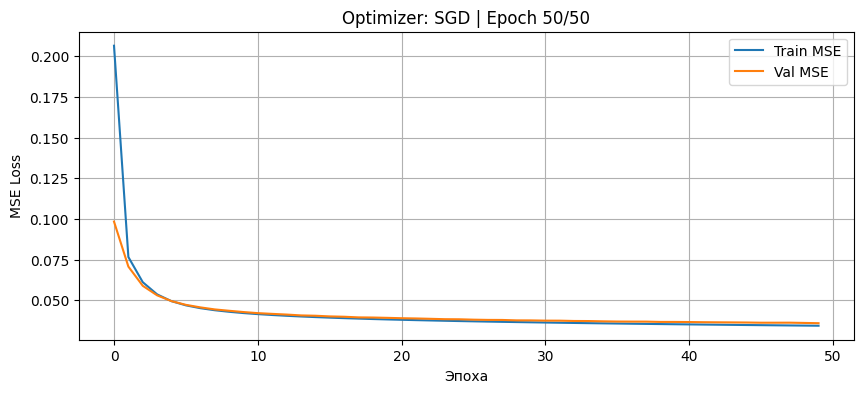

Эпоха 50/50 | Train Loss: 0.0343 | Val Loss: 0.0359


In [ ]:
train_losses_sgd, val_losses_sgd = train_and_evaluate(
    model, train_loader, val_loader, optimizer_type='sgd', lr=0.0005
)

=== Метрики качества: MLP ===
MSE : 5.2209
MAE : 1.7688 °C
R²  : 0.9606


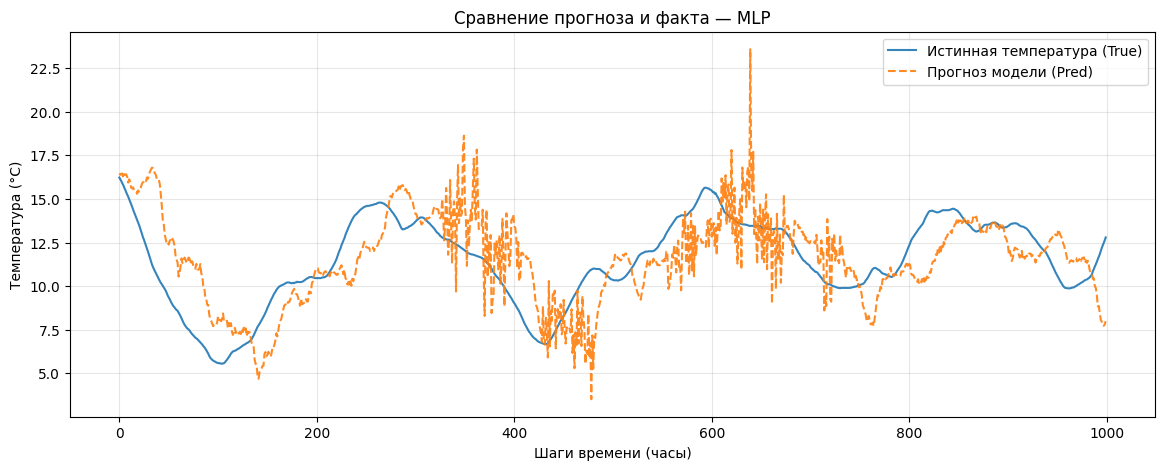

In [ ]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=1000
)

In [ ]:
input_dim = X_train.shape[1]
set_seed(42)

model_adam = SimpleWeatherMLP(input_dim=input_dim, hidden_dim=128)

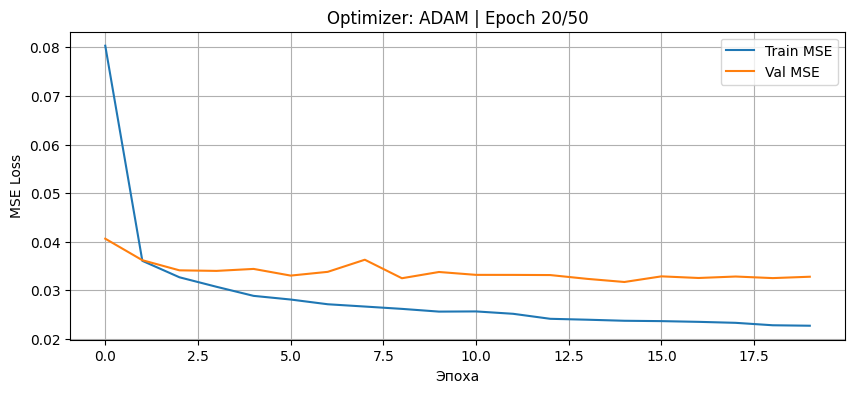

Эпоха 20/50 | Train Loss: 0.0227 | Val Loss: 0.0328
Ранняя остановка сработала на эпохе 20


In [ ]:
train_losses_adam, val_losses_adam = train_and_evaluate(
    model_adam, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: MLP ===
MSE : 4.7728
MAE : 1.7003 °C
R²  : 0.9640


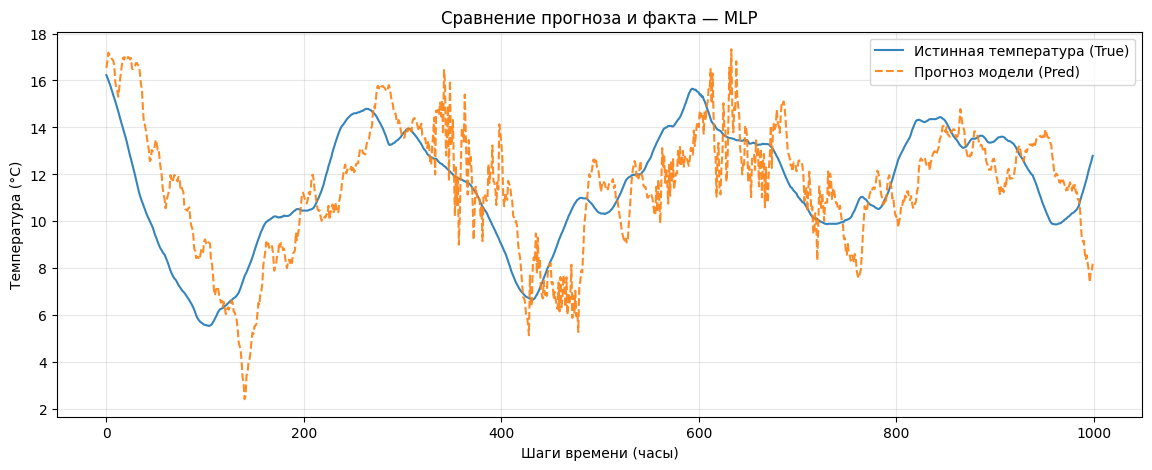

In [ ]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_adam,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=1000
)

In [ ]:
import torch
import torch.nn as nn

class TwoLayerDropoutWeatherMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2):
        super(TwoLayerDropoutWeatherMLP, self).__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate)

        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate)

        self.fc3 = nn.Linear(hidden_dim2, 1)  # Выходной слой

    def forward(self, x):
        x = self.drop1(self.act1(self.fc1(x)))
        x = self.drop2(self.act2(self.fc2(x)))
        x = self.fc3(x)
        return x

# Инициализация модели с Dropout (например, с вероятностью отключения 20%)
set_seed(42)
input_dim = X_train.shape[1]
model_dropout = TwoLayerDropoutWeatherMLP(input_dim=input_dim, hidden_dim1=128, hidden_dim2=64, dropout_rate=0.2)

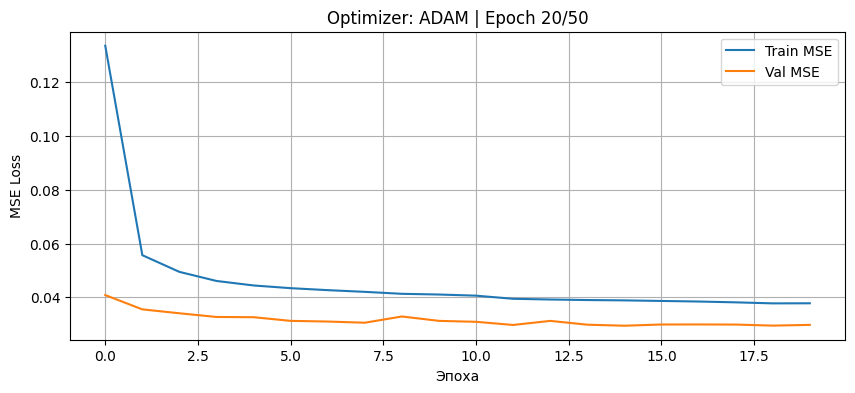

Эпоха 20/50 | Train Loss: 0.0378 | Val Loss: 0.0298
Ранняя остановка сработала на эпохе 20


In [ ]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_dropout, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: MLP ===
MSE : 4.3336
MAE : 1.6341 °C
R²  : 0.9673


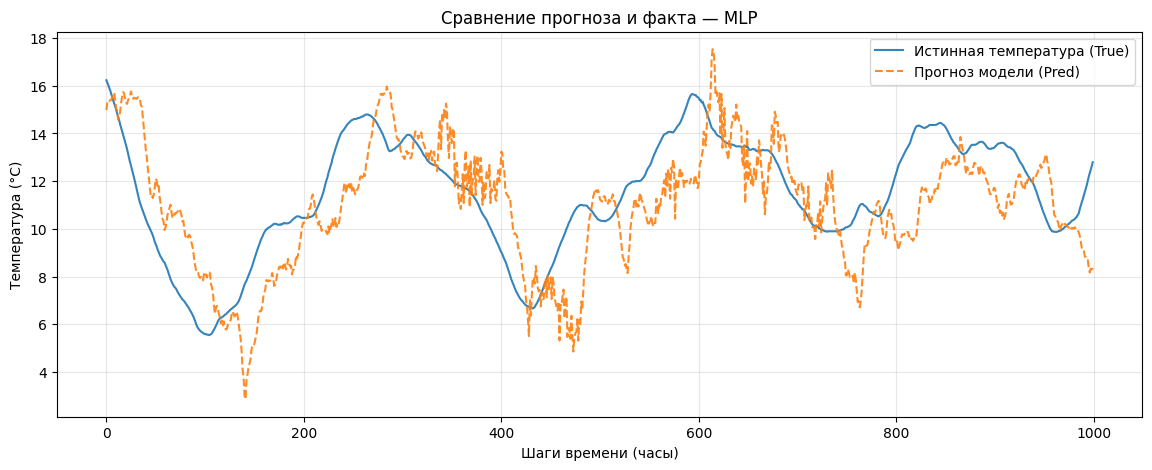

In [ ]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_dropout,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=1000
)

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test, scaler_x, scaler_y = prepare_rnn_data(data, L_days=7)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Создаем датасеты
train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

# Создаем батчи (формат батча X будет [Batch_Size, 168, Num_Features])
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False) # Для RNN обычно shuffle=False или True, но для временных рядов без перемешивания безопаснее
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

In [ ]:
import torch
import torch.nn as nn

class SimpleGRUWeatherModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=1, dropout=0.2):
        super(SimpleGRUWeatherModel, self).__init__()

        # Рекуррентный слой GRU
        # batch_first=True означает, что размерность батча идет первой: [Batch, Seq_Len, Features]
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Полносвязный слой для проецирования скрытого состояния в одно число (температуру)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x имеет форму: [Batch, Seq_Len, Features]

        # out: [Batch, Seq_Len, hidden_dim] — выходы со всех шагов последовательности
        # h_n: [num_layers, Batch, hidden_dim] — последнее скрытое состояние
        out, h_n = self.gru(x)

        # Берем скрытое состояние только с самого последнего временного шага последовательности
        # h_n[-1] имеет форму: [Batch, hidden_dim]
        last_hidden = h_n[-1]

        # Прогоняем через линейный слой -> [Batch, 1]
        prediction = self.fc(last_hidden)

        return prediction

# Инициализация модели (input_dim — количество признаков в вашем DataFrame)
set_seed(42)
input_dim = X_train.shape[2]  # Для 3D тензора признаков [Batch, Len, Features]
model_gru = SimpleGRUWeatherModel(input_dim=input_dim, hidden_dim=64, num_layers=1)

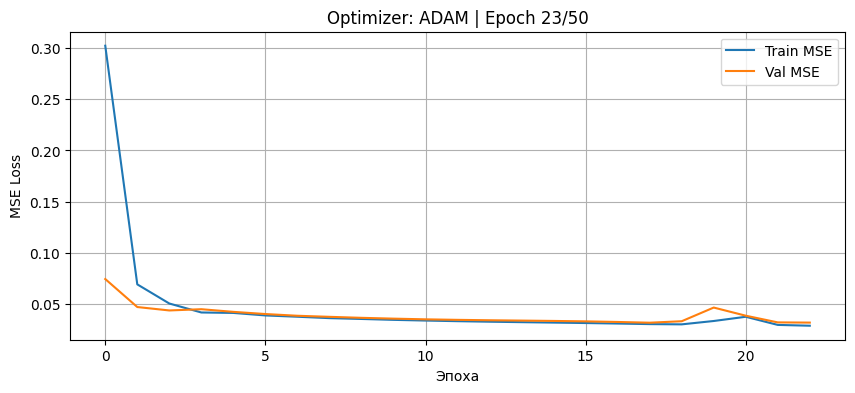

Эпоха 23/50 | Train Loss: 0.0288 | Val Loss: 0.0319
Ранняя остановка сработала на эпохе 23


In [ ]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_gru, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: MLP ===
MSE : 4.6357
MAE : 1.6680 °C
R²  : 0.9650


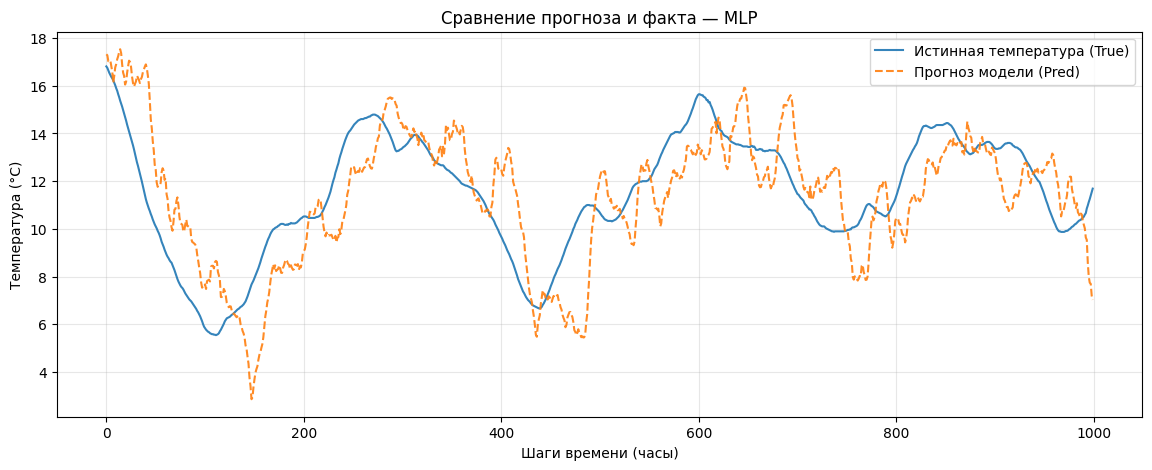

In [ ]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=1000
)

=== Метрики качества: MLP ===
MSE : 4.8170
MAE : 1.6912 °C
R²  : 0.9563


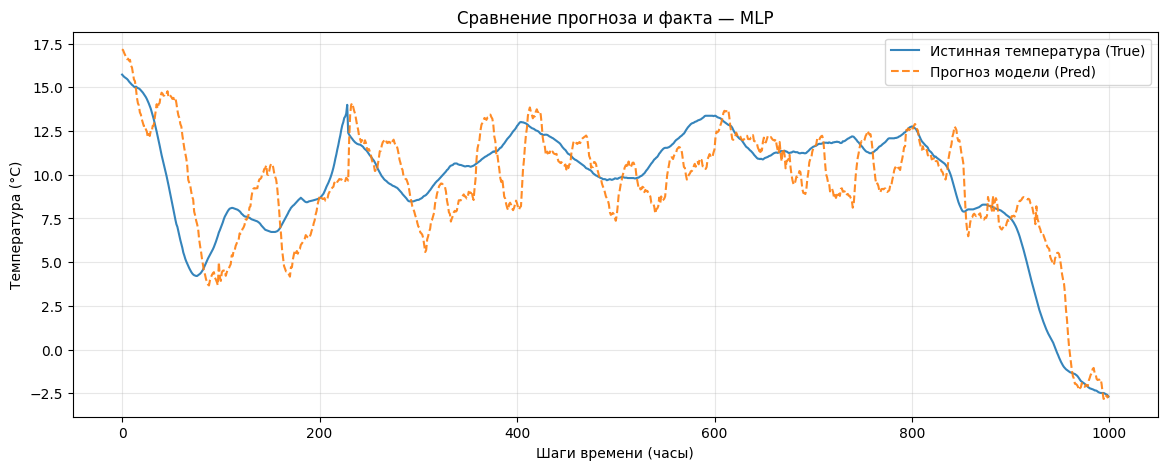

In [ ]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru,       # любая ваша модель (MLP или RNN)
    data_loader=test_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=1000
)